# code_079 · Posterior computation and model checking

**Book:** section 16.3. A self-contained probabilistic response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_16_GUIDE.md), [run evidence](../CHAPTER_16_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_079).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1679;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1679


<a id="computation"></a>
## Compare computations for one declared posterior

Use the same eight-building counts and truncated Beta–Binomial hierarchy as code_078, repeated here without file dependencies. Conditional group rates have conjugate Beta distributions; the two hyperparameters need joint numerical integration. A61x61 trapezoid grid supplies a bounded numerical reference, not an exact analytic answer. Compare iid draws from its cell masses, a fixed four-chain random-walk Metropolis run and a categorical mean-field approximation on that same grid. The MCMC coordinates are theta=logit(m),v=log(k); its density includes the m*(1-m) transformation Jacobian. Priors and bounds remain fixed. Classical split Rhat and a simple autocorrelation ESS are teaching diagnostics, not modern rank-normalized Stan diagnostics or proof of convergence.


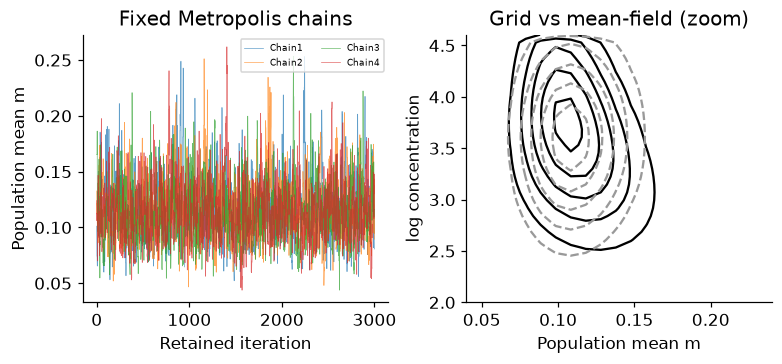

In [2]:
from scipy.special import betaln,logsumexp,expit,logit
from scipy.stats import beta as beta_distribution,norm
n=np.array([4,8,12,20,40,80,160,320]);s=np.array([0,1,3,1,5,9,10,30]);m_grid=np.linspace(.01,.6,61);v_grid=np.linspace(0,np.log(100),61);M,V=np.meshgrid(m_grid,v_grid,indexing='ij');K=np.exp(V);a=M*K;b=(1-M)*K
trap=np.ones(61);trap[[0,-1]]=.5;log_cells=np.log(trap[:,None]*trap[None,:]);log_prior_density=beta_distribution.logpdf(M,2,8)+norm.logpdf(V,np.log(20),.8)
log_likelihood=np.sum(betaln(a[:,:,None]+s,b[:,:,None]+n-s)-betaln(a,b)[:,:,None],axis=2);prior_logmass=log_prior_density+log_cells;prior_mass=np.exp(prior_logmass-logsumexp(prior_logmass));posterior_logmass=prior_logmass+log_likelihood;posterior_mass=np.exp(posterior_logmass-logsumexp(posterior_logmass))
assert np.isclose(prior_mass.sum(),1) and np.isclose(posterior_mass.sum(),1);assert np.all((s>=0)&(s<=n))
conditional_mean=(s[None,None,:]+a[:,:,None])/(n[None,None,:]+K[:,:,None]);group_mean=np.sum(posterior_mass[:,:,None]*conditional_mean,axis=(0,1))
# A denser independent quadrature checks the reported group means.
fm,fv=np.meshgrid(np.linspace(.01,.6,121),np.linspace(0,np.log(100),121),indexing='ij');fk=np.exp(fv);fa=fm*fk;fb=(1-fm)*fk;ft=np.ones(121);ft[[0,-1]]=.5
fl=beta_distribution.logpdf(fm,2,8)+norm.logpdf(fv,np.log(20),.8)+np.log(ft[:,None]*ft[None,:])+np.sum(betaln(fa[:,:,None]+s,fb[:,:,None]+n-s)-betaln(fa,fb)[:,:,None],axis=2);fw=np.exp(fl-logsumexp(fl));fine_mean=np.sum(fw[:,:,None]*(s[None,None,:]+fa[:,:,None])/(n[None,None,:]+fk[:,:,None]),axis=(0,1));refinement_error=float(np.max(np.abs(fine_mean-group_mean)));assert refinement_error<.001
RESULTS['grid_refinement']={'coarse_points_per_axis':61,'fine_points_per_axis':121,'max_group_posterior_mean_difference':refinement_error,'posterior_continuous_integration_exact':False}

def draw_groups(mass,draws):
 ids=rng.choice(mass.size,draws,p=mass.ravel());aa=a.ravel()[ids,None];bb=b.ravel()[ids,None];return ids,rng.beta(aa+s,bb+n-s)

def log_density(q):
 theta,v=q;m=expit(theta)
 if not (.01<=m<=.6 and 0<=v<=np.log(100)):return -np.inf
 k=np.exp(v);aa=m*k;bb=(1-m)*k;return float(beta_distribution.logpdf(m,2,8)+norm.logpdf(v,np.log(20),.8)+np.sum(betaln(aa+s,bb+n-s)-betaln(aa,bb))+np.log(m)+np.log1p(-m))
chains=[];acceptance=[];warmup=1000;kept=3000
for chain in range(4):
 q=np.array([logit(.07+.04*chain),np.log(8+12*chain)]);value=log_density(q);draws=[];accepted=0
 for step in range(warmup+kept):
  candidate=q+rng.normal(size=2)*np.array([.3,.3]);proposed=log_density(candidate)
  if np.log(rng.uniform())<proposed-value:q=candidate;value=proposed;accepted+=1
  if step>=warmup:draws.append([expit(q[0]),q[1]])
 chains.append(draws);acceptance.append(accepted/(warmup+kept))
chains=np.array(chains);assert chains.shape==(4,3000,2) and np.isfinite(chains).all();assert all(0<x<1 for x in acceptance)
def split_rhat(x):
 half=x.shape[1]//2;z=np.concatenate([x[:,:half],x[:,half:]],axis=0);within=z.var(axis=1,ddof=1).mean();between=half*z.mean(axis=1).var(ddof=1);return float(np.sqrt(((half-1)/half*within+between/half)/within))
def simple_ess(x):
 # Average within-chain autocorrelation; stop at first nonpositive adjacent-lag pair.
 nchain,length=x.shape;center=x-x.mean(axis=1,keepdims=True);den=np.sum(center**2,axis=1);rho=[]
 for lag in range(1,min(length//2,1000)):
  rho.append(float(np.mean(np.sum(center[:,:-lag]*center[:,lag:],axis=1)/den)))
  if len(rho)%2==0 and rho[-1]+rho[-2]<=0:rho=rho[:-2];break
 return float(nchain*length/max(1,1+2*sum(rho)))
# Coordinate-ascent reverse-KL mean-field approximation to grid cell masses.
log_joint=posterior_logmass-logsumexp(posterior_logmass);qm=np.ones(61)/61;qv=np.ones(61)/61
for iteration in range(2000):
 old=np.r_[qm,qv];lm=log_joint@qv;qm=np.exp(lm-logsumexp(lm));lv=qm@log_joint;qv=np.exp(lv-logsumexp(lv))
 if np.max(np.abs(old-np.r_[qm,qv]))<1e-12:break
qvi=qm[:,None]*qv[None,:];assert np.isclose(qvi.sum(),1)
reference=np.array([np.sum(posterior_mass*M),np.sum(posterior_mass*V)]);grid_ids=rng.choice(posterior_mass.size,12000,p=posterior_mass.ravel());iid=np.column_stack([M.ravel()[grid_ids],V.ravel()[grid_ids]]);vi_mean=np.array([np.sum(qvi*M),np.sum(qvi*V)]);ref_sd=np.sqrt([np.sum(posterior_mass*(M-reference[0])**2),np.sum(posterior_mass*(V-reference[1])**2)]);vi_sd=np.sqrt([np.sum(qvi*(M-vi_mean[0])**2),np.sum(qvi*(V-vi_mean[1])**2)])
RESULTS['computation']={'reference_mean_m_logk':reference.tolist(),'iid_grid_draw_mean':iid.mean(axis=0).tolist(),'mcmc_mean_m_logk':chains.mean(axis=(0,1)).tolist(),'chain_acceptance':acceptance,'classical_split_Rhat':[split_rhat(chains[:,:,j]) for j in range(2)],'simple_within_chain_ESS':[simple_ess(chains[:,:,j]) for j in range(2)],'warmup_per_chain':1000,'retained_per_chain':3000,'mean_field_mean_m_logk':vi_mean.tolist(),'reference_sd_m_logk':ref_sd.tolist(),'mean_field_sd_m_logk':vi_sd.tolist(),'mean_field_iterations':iteration+1,'posterior_last_concentration_grid_column_mass':float(posterior_mass[:,-1].sum())}
fig,axes=plt.subplots(1,2,figsize=(7,3.2))
for j in range(4):axes[0].plot(np.arange(kept),chains[j,:,0],lw=.45,alpha=.7,label=f'Chain{j+1}')
axes[0].set(xlabel='Retained iteration',ylabel='Population mean m',title='Fixed Metropolis chains');axes[0].legend(fontsize=6,ncol=2);axes[1].contour(M,V,posterior_mass,levels=5,colors='black');axes[1].contour(M,V,qvi,levels=5,colors='.6',linestyles='--');axes[1].set(xlabel='Population mean m',ylabel='log concentration',title='Grid vs mean-field (zoom)',xlim=(.04,.24),ylim=(2,4.605170185988092));plt.show()


<a id="criticism"></a>
## Sampling diagnostics and model criticism ask different questions

Draw latent group rates from the posterior grid mixture and replicate failures at the original inspection counts. Compare the unweighted variance of observed group rates with replicated rate variance. Small groups contribute Binomial sampling variation, which the replications retain. A tail fraction is a posterior predictive discrepancy summary, not an independent-test p-value or a probability that the model is true. Reusing observed outcomes is intentional model criticism, not held-out predictive assessment. No MCMC diagnostic alone checks exchangeability, failure ascertainment or the prior bounds.


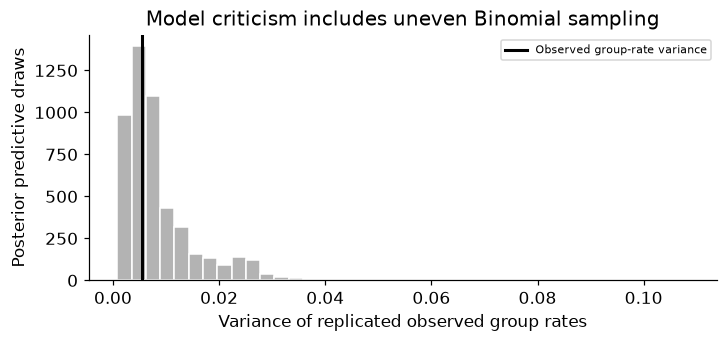

In [3]:
ids,p_draw=draw_groups(posterior_mass,5000);rep=rng.binomial(n[None,:],p_draw);observed=float(np.var(s/n,ddof=1));discrepancy=np.var(rep/n[None,:],axis=1,ddof=1);assert rep.shape==(5000,8) and np.all(rep<=n[None,:]);RESULTS['posterior_predictive_check']={'statistic':'unweighted variance of group observed rates','observed':observed,'replicated_mean':float(discrepancy.mean()),'replicated_2_5_97_5':np.quantile(discrepancy,[.025,.975]).tolist(),'replicated_fraction_ge_observed':float(np.mean(discrepancy>=observed)),'independent_assessment':False,'draws':5000}
fig,ax=plt.subplots(figsize=(6.5,3));ax.hist(discrepancy,bins=40,color='.7',edgecolor='white');ax.axvline(observed,color='black',lw=2,label='Observed group-rate variance');ax.set(xlabel='Variance of replicated observed group rates',ylabel='Posterior predictive draws',title='Model criticism includes uneven Binomial sampling');ax.legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_079','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['conjugate conditional and joint grid reference', 'transformed random-walk MCMC with Jacobian', 'classical split Rhat and simple ESS', 'mean-field grid approximation and predictive criticism'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["conjugate conditional and joint grid reference", "transformed random-walk MCMC with Jacobian", "classical split Rhat and simple ESS", "mean-field grid approximation and predictive criticism"], "elapsed_seconds": 0.82, "example_id": "code_079", "hardware": "Darwin arm64 CPU", "results": {"computation": {"chain_acceptance": [0.58975, 0.59525, 0.61275, 0.6015], "classical_split_Rhat": [1.0020965472343628, 1.0040228137294058], "iid_grid_draw_mean": [0.11483726388888965, 3.510470064221086], "mcmc_mean_m_logk": [0.1153996171504399, 3.4771607556958974], "mean_field_iterations": 14, "mean_field_mean_m_logk": [0.11157594538246068, 3.538782668482428], "mean_field_sd_m_logk": [0.02398312115434151, 0.5528290880329282], "posterior_last_concentration_grid_column_mass": 0.008441130578302106, "reference_mean_m_logk": [0.1144995083644458, 3.512889743597202], "reference_sd_m_logk": [0.02760820719345163, 0.5897203796974916], "retained_per_chain": 3000, "